# 01 - Preprocesamiento de datos
Proyecto Final de Minería de Datos
Análisis de la intención de compra en comercio electrónico (Online Shoppers Purchasing Intention Dataset, UCI)

Responsable: Juan Pablo Moreno Cruz

## Notas para el equipo

Este notebook limpia y prepara el dataset y deja tres archivos en `data/`. No hace falta volver a limpiar los datos, solo leer el CSV que corresponda a su parte.

| Archivo | Para quién | Contenido |
|---|---|---|
| `data/datos_limpios.csv` | Regresión y Clustering | Datos limpios, sin escalar, con categorías legibles y variables nuevas |
| `data/datos_codificados.csv` | Clasificación | Lo mismo, pero con one-hot encoding (`drop_first=True`) en las variables nominales |
| `data/datos_discretizados.csv` | Reglas de asociación | Variables numéricas convertidas a categorías (bajo / medio / alto), en formato de ítems |

Acuerdos válidos para los tres archivos:
- `Revenue` y `Weekend` están como 0/1.
- La columna `conjunto` indica la partición: `train` (80 %) o `test` (20 %), estratificada por `Revenue` con `random_state=42`. Todos usamos esa misma partición. No es una característica, hay que quitarla de `X`.
- No hay escalado en los CSV. Si el modelo lo necesita (K-Means, SVM, regresión logística), ajustar el escalador solo con `train` y aplicarlo a `test`.
- Los outliers no se eliminaron (ver 2.8).
- `OperatingSystems`, `Browser`, `Region` y `TrafficType` son códigos nominales, no cantidades.
- Regresión (objetivo `ProductRelated_Duration`): excluir `TotalDuration` y `AvgTimePerPage`, porque se calculan a partir del objetivo.

## 0. Configuración

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

# Parámetros del proyecto (no cambiar sin avisar al equipo)
RANDOM_STATE = 42
TEST_SIZE = 0.20
RUTA_CSV = "data/online_shoppers_intention.csv"
ELIMINAR_DUPLICADOS = True

## 1. Carga de datos

In [2]:
if not os.path.exists(RUTA_CSV):
    print("No se encontró", RUTA_CSV, "| archivos en data/:", os.listdir("data"))

df_raw = pd.read_csv(RUTA_CSV)
df = df_raw.copy()
print("Filas, columnas:", df.shape)
df.head()

Filas, columnas: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0000,0,0.0000,2,64.0000,0.0000,0.1000,0.0000,0.0000,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0000,0,0.0000,2,2.6667,0.0500,0.1400,0.0000,0.0000,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0000,0,0.0000,10,627.5000,0.0200,0.0500,0.0000,0.0000,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
# Grupos de variables
COLS_CONTEO    = ["Administrative", "Informational", "ProductRelated"]
COLS_DURACION  = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]
COLS_TASAS     = ["BounceRates", "ExitRates"]
COLS_NUM       = COLS_CONTEO + COLS_DURACION + COLS_TASAS + ["PageValues", "SpecialDay"]
COLS_NOMINALES = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]

## 2. Preprocesamiento

### 2.1 Tipos de datos y valores faltantes

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [5]:
print("Valores nulos por columna")
print(df.isnull().sum())

faltantes = pd.DataFrame({
    "Cantidad": df.isna().sum(),
    "Porcentaje": (df.isna().mean() * 100).round(2)
})
faltantes[faltantes["Cantidad"] > 0]

Valores nulos por columna
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


,Cantidad,Porcentaje


### 2.2 Registros duplicados

In [6]:
print("Registros duplicados:", df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

Registros duplicados: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
8247,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Dec,1,1,1,1,Returning_Visitor,True,False
10751,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Dec,1,1,1,1,Returning_Visitor,True,False
11658,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Dec,1,1,1,1,Returning_Visitor,True,False
8882,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Dec,1,1,1,2,New_Visitor,False,False
11934,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Dec,1,1,1,2,New_Visitor,False,False
11110,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Dec,1,1,1,3,Returning_Visitor,False,False


### 2.3 Consistencia y valores fuera de rango

In [7]:
print("Valores negativos por columna numérica")
neg = (df[COLS_NUM] < 0).sum()
print(neg[neg > 0] if neg.sum() > 0 else "Ninguno")

print("\nTasas fuera de [0, 1]")
print(((df[COLS_TASAS] < 0) | (df[COLS_TASAS] > 1)).sum().to_dict())

print("\nSpecialDay fuera de [0, 1]")
print(((df["SpecialDay"] < 0) | (df["SpecialDay"] > 1)).sum())

print("\nPáginas vs. duración")
for c, d in zip(COLS_CONTEO, COLS_DURACION):
    a = ((df[c] == 0) & (df[d] > 0)).sum()
    b = ((df[c] > 0) & (df[d] == 0)).sum()
    print(f"{c:15s} | conteo = 0 y duración > 0: {a:5d} | conteo > 0 y duración = 0: {b:5d}")

print("\nValores únicos de las categorías de texto")
print("Month:", sorted(df["Month"].astype(str).unique()))
print("VisitorType:", sorted(df["VisitorType"].astype(str).unique()))
print("Weekend:", df["Weekend"].unique(), "| Revenue:", df["Revenue"].unique())

Valores negativos por columna numérica
Ninguno

Tasas fuera de [0, 1]
{'BounceRates': 0, 'ExitRates': 0}

SpecialDay fuera de [0, 1]
0

Páginas vs. duración
Administrative  | conteo = 0 y duración > 0:     0 | conteo > 0 y duración = 0:   135
Informational   | conteo = 0 y duración > 0:     0 | conteo > 0 y duración = 0:   226
ProductRelated  | conteo = 0 y duración > 0:     0 | conteo > 0 y duración = 0:   717

Valores únicos de las categorías de texto
Month: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
VisitorType: ['New_Visitor', 'Other', 'Returning_Visitor']
Weekend: [False  True] | Revenue: [False  True]


Observaciones: No se presnetan valores negativos

### 2.4 Limpieza
Decisiones:
1. Duraciones negativas se pasan a 0 (no tienen sentido físico).
2. Se unifican los nombres de mes (`June` a `Jun`) y `Month` queda como categoría ordenada.
3. `Weekend` y `Revenue` pasan a 0/1.
4. Se eliminan los duplicados exactos (se controla con `ELIMINAR_DUPLICADOS`). El total queda por debajo de las 12,330 filas originales.

In [8]:
n_original = len(df)

# Duraciones negativas a 0
for c in COLS_DURACION:
    n_neg = (df[c] < 0).sum()
    if n_neg:
        df.loc[df[c] < 0, c] = 0
    print(f"{c}: {n_neg} valores negativos corregidos")

# Texto limpio y meses unificados
for c in ["Month", "VisitorType"]:
    df[c] = df[c].astype(str).str.strip()
df["Month"] = df["Month"].replace({"June": "Jun"})

orden_meses = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
meses_presentes = [m for m in orden_meses if m in df["Month"].unique()]
df["Month"] = pd.Categorical(df["Month"], categories=meses_presentes, ordered=True)

# Booleanos a 0/1
for c in ["Weekend", "Revenue"]:
    df[c] = df[c].astype(str).str.lower().map({"true": 1, "false": 0}).astype(int)

# Duplicados
if ELIMINAR_DUPLICADOS:
    df = df.drop_duplicates()
df = df.reset_index(drop=True)

print(f"\nRegistros antes: {n_original}")
print(f"Registros después: {len(df)}")
print(f"Registros duplicados eliminados: {n_original - len(df)}")

Administrative_Duration: 0 valores negativos corregidos
Informational_Duration: 0 valores negativos corregidos
ProductRelated_Duration: 0 valores negativos corregidos

Registros antes: 12330
Registros después: 12205
Registros duplicados eliminados: 125


### 2.5 Tratamiento de datos faltantes

In [9]:
# Mediana para numéricas y moda para categóricas.
# En este dataset no hay nulos, pero se deja el tratamiento por si cambia la fuente.
for c in COLS_NUM:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].median())

for c in ["Month", "VisitorType"]:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mode()[0])

print("Nulos restantes:", df.isna().sum().sum())

Nulos restantes: 0


### 2.6 Validación de valores imposibles

In [10]:
umbrales = {c: {"min": 0, "max": np.inf} for c in COLS_CONTEO + COLS_DURACION + ["PageValues"]}
umbrales.update({c: {"min": 0, "max": 1} for c in COLS_TASAS + ["SpecialDay"]})

for v, lim in umbrales.items():
    invalidos = ~df[v].between(lim["min"], lim["max"])
    print(f"{v:25s} valores imposibles: {invalidos.sum()}")

Administrative            valores imposibles: 0
Informational             valores imposibles: 0
ProductRelated            valores imposibles: 0
Administrative_Duration   valores imposibles: 0
Informational_Duration    valores imposibles: 0
ProductRelated_Duration   valores imposibles: 0
PageValues                valores imposibles: 0
BounceRates               valores imposibles: 0
ExitRates                 valores imposibles: 0
SpecialDay                valores imposibles: 0


### 2.7 Detección de valores atípicos
Se usa el criterio IQR: valores fuera de [Q1 - 1.5 IQR, Q3 + 1.5 IQR].

In [11]:
def detectar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    mascara = (serie < limite_inferior) | (serie > limite_superior)
    return mascara, limite_inferior, limite_superior

filas = []
for v in COLS_NUM:
    mascara, li, ls = detectar_outliers_iqr(df[v])
    filas.append({"variable": v, "lim_inf": li, "lim_sup": ls,
                  "n_outliers": mascara.sum(), "% outliers": mascara.mean() * 100})
pd.DataFrame(filas).set_index("variable")

,lim_inf,lim_sup,n_outliers,% outliers
variable,,,,
Administrative,-6.0000,10.0000,404,3.3101
Informational,0.0000,0.0000,2631,21.5567
ProductRelated,-37.0000,83.0000,1007,8.2507
Administrative_Duration,-142.0500,236.7500,1149,9.4142
Informational_Duration,0.0000,0.0000,2405,19.7050
ProductRelated_Duration,"-1,733.2321","3,403.3869",951,7.7919
BounceRates,-0.0250,0.0417,1428,11.7001
ExitRates,-0.0372,0.1000,1325,10.8562
PageValues,0.0000,0.0000,2730,22.3679


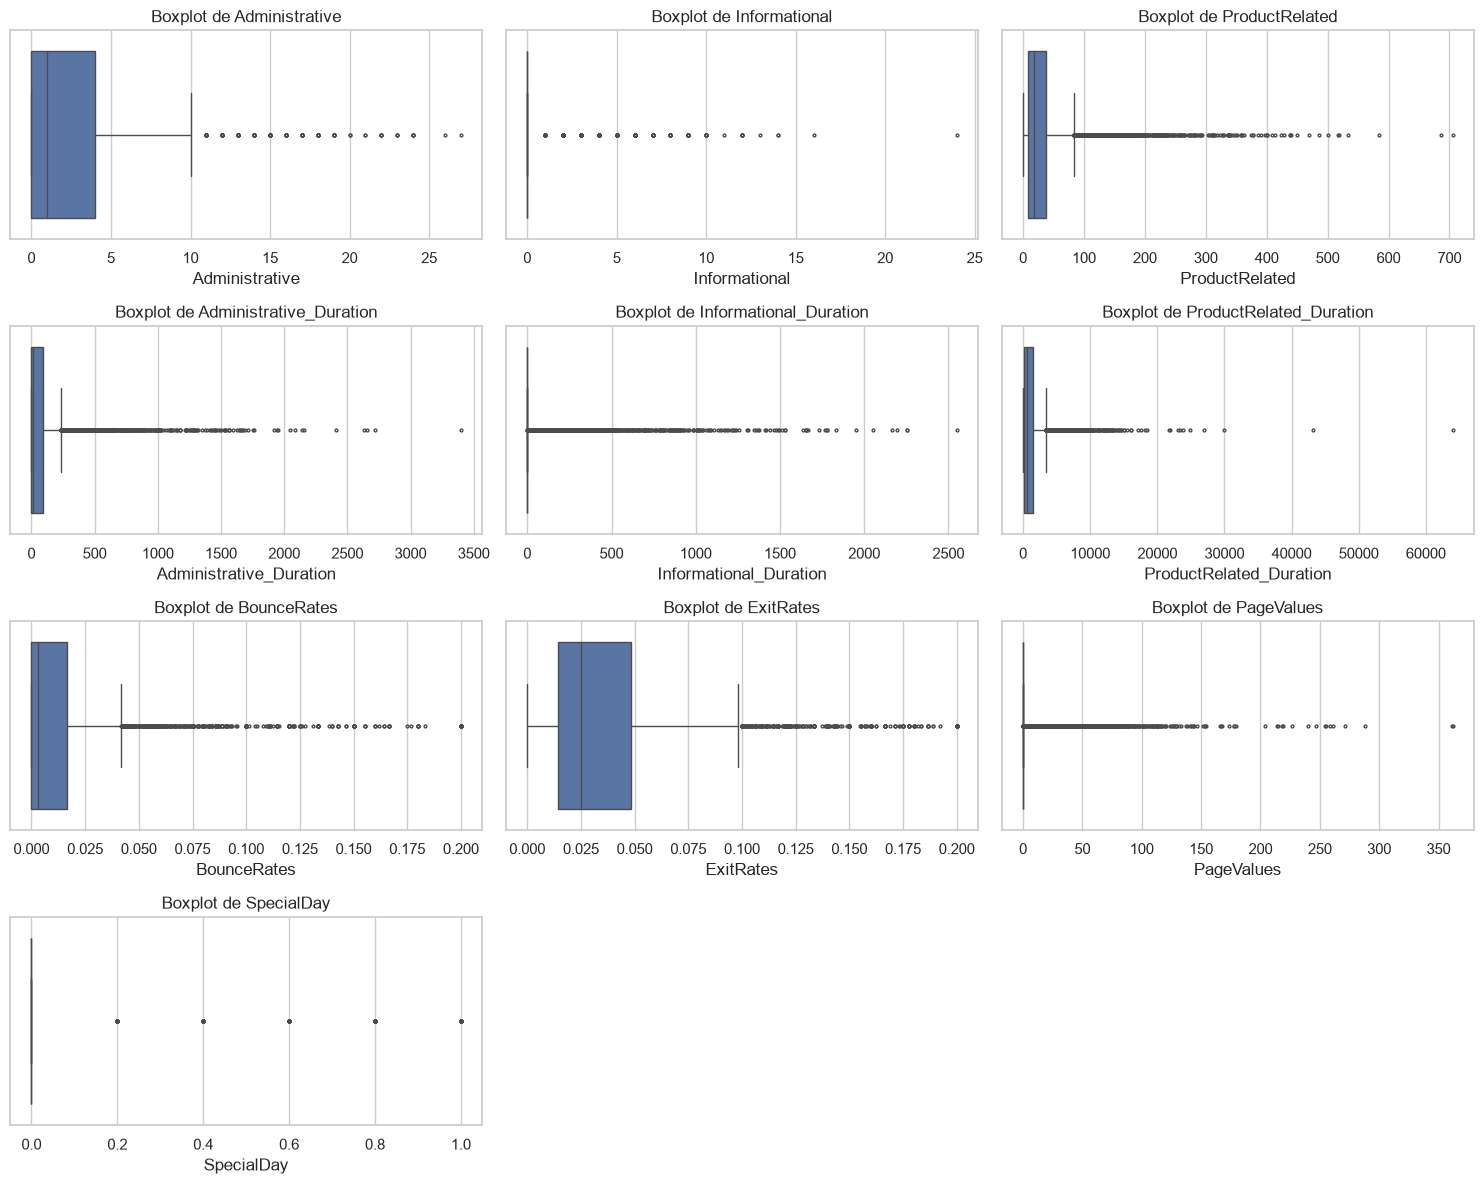

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, v in zip(axes.ravel(), COLS_NUM):
    sns.boxplot(x=df[v], ax=ax, fliersize=2)
    ax.set_title(f"Boxplot de {v}")
for ax in axes.ravel()[len(COLS_NUM):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [13]:
# Asimetría
df[COLS_NUM].skew().sort_values(ascending=False).to_frame("skewness")

,skewness
Informational_Duration,7.5403
ProductRelated_Duration,7.2532
PageValues,6.3510
Administrative_Duration,5.5922
ProductRelated,4.3334
Informational,4.0142
SpecialDay,3.2859
BounceRates,3.1624
ExitRates,2.2346
Administrative,1.9471


Observaciones:

### 2.8 Tratamiento de valores atípicos
Los outliers no se eliminan en los archivos que usa el equipo. Muchas de estas variables tienen colas largas y muchos ceros, y las sesiones largas son comportamiento real (justo las que interesan para predecir la compra).
Además, aplicar el recorte a todas las variables sería un error. En variables donde más del 75 % de las sesiones vale 0 (como `Informational_Duration` y, probablemente, `PageValues`), Q1 y Q3 son 0, el IQR es 0 y el límite superior también: el recorte convierte toda la variable en ceros. La demostración de abajo lo muestra con `Informational_Duration`.

Aquí se muestra el efecto del recorte al límite IQR (`clip`) solo en las duraciones, sobre una copia.

In [26]:
df_clip = df.copy()
for v in COLS_DURACION:
    mascara, li, ls = detectar_outliers_iqr(df[v])
    print(f"{v}: límite superior = {ls:.2f}")
    df_clip[v] = df[v].clip(lower=li, upper=ls)

antes = df[COLS_DURACION].describe().T[["mean", "std", "max"]].add_suffix("_antes")
despues = df_clip[COLS_DURACION].describe().T[["mean", "std", "max"]].add_suffix("_despues")
pd.concat([antes, despues], axis=1)

Administrative_Duration: límite superior = 236.75
Informational_Duration: límite superior = 0.00
ProductRelated_Duration: límite superior = 3403.39


,mean_antes,std_antes,max_antes,mean_despues,std_despues,max_despues
Administrative_Duration,81.6463,177.4918,"3,398.7500",57.8995,80.2064,236.7500
Informational_Duration,34.8255,141.4248,"2,549.3750",0.0000,0.0000,0.0000
ProductRelated_Duration,"1,206.9825","1,919.6014","63,973.5222","1,001.3326","1,036.9854","3,403.3869"


## 3. Creación de variables

| Variable | Definición |
|---|---|
| `TotalPages` | Administrative + Informational + ProductRelated |
| `NonProductDuration` | Administrative_Duration + Informational_Duration |
| `ProductPageRatio` | ProductRelated / TotalPages (0 si no hubo páginas) |
| `TotalDuration` | suma de las tres duraciones (incluye el objetivo de Regresión) |
| `AvgTimePerPage` | TotalDuration / TotalPages (incluye el objetivo de Regresión) |
| `IsSpecialDay` | 1 si SpecialDay > 0 |
| `HasPageValue` | 1 si PageValues > 0 |

In [15]:
df["TotalPages"] = df[COLS_CONTEO].sum(axis=1)
df["NonProductDuration"] = df["Administrative_Duration"] + df["Informational_Duration"]
df["ProductPageRatio"] = df["ProductRelated"].div(df["TotalPages"].replace(0, np.nan)).fillna(0)
df["TotalDuration"] = df[COLS_DURACION].sum(axis=1)
df["AvgTimePerPage"] = df["TotalDuration"].div(df["TotalPages"].replace(0, np.nan)).fillna(0)
df["IsSpecialDay"] = (df["SpecialDay"] > 0).astype(int)
df["HasPageValue"] = (df["PageValues"] > 0).astype(int)

COLS_NUEVAS = ["TotalPages", "NonProductDuration", "ProductPageRatio", "TotalDuration",
               "AvgTimePerPage", "IsSpecialDay", "HasPageValue"]

df[COLS_NUEVAS].describe().T

,count,mean,std,min,25%,50%,75%,max
TotalPages,"12,205.0000",34.8932,46.6273,0.0000,9.0000,20.0000,42.0000,746.0000
NonProductDuration,"12,205.0000",116.4718,251.8197,0.0000,0.0000,20.0000,123.0000,"5,948.1250"
ProductPageRatio,"12,205.0000",0.9041,0.1423,0.0000,0.8571,0.9615,1.0000,1.0000
TotalDuration,"12,205.0000","1,323.4542","2,043.8716",0.0000,231.6667,690.9583,"1,643.9583","69,921.6472"
AvgTimePerPage,"12,205.0000",38.1791,43.4729,0.0000,18.5556,29.9708,45.6883,"1,411.0000"
IsSpecialDay,"12,205.0000",0.1023,0.3031,0.0000,0.0000,0.0000,0.0000,1.0000
HasPageValue,"12,205.0000",0.2237,0.4167,0.0000,0.0000,0.0000,0.0000,1.0000


## 4. Preparación para los modelos

### 4.1 Partición entrenamiento / prueba
Una sola partición para todo el equipo: 80 / 20, estratificada por `Revenue`, con `random_state=42`. Se guarda en la columna `conjunto`.

In [16]:
idx_train, idx_test = train_test_split(
    df.index, test_size=TEST_SIZE, stratify=df["Revenue"], random_state=RANDOM_STATE
)
df["conjunto"] = "train"
df.loc[idx_test, "conjunto"] = "test"

print(df["conjunto"].value_counts().to_string())
print("\nTasa de compra por conjunto:")
print(df.groupby("conjunto")["Revenue"].mean().round(4).to_string())

conjunto
train    9764
test     2441

Tasa de compra por conjunto:
conjunto
test    0.1565
train   0.1563


### 4.2 Codificación de variables categóricas
One-hot encoding para las variables nominales, con `drop_first=True` para evitar colinealidad. No se usa label encoding porque ninguna de estas variables tiene un orden que signifique algo para el modelo.

In [17]:
df_cod = pd.get_dummies(df, columns=COLS_NOMINALES, drop_first=True, dtype=int)
print("Columnas antes:", df.shape[1], "| después del one-hot:", df_cod.shape[1])
df_cod.head()

Columnas antes: 26 | después del one-hot: 77


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Weekend,Revenue,TotalPages,NonProductDuration,ProductPageRatio,TotalDuration,AvgTimePerPage,IsSpecialDay,HasPageValue,conjunto,Month_Mar,Month_May,Month_Jun,Month_Jul,Month_Aug,Month_Sep,Month_Oct,Month_Nov,Month_Dec,VisitorType_Other,...,Browser_11,Browser_12,Browser_13,Region_2,Region_3,Region_4,Region_5,Region_6,Region_7,Region_8,Region_9,TrafficType_2,TrafficType_3,TrafficType_4,TrafficType_5,TrafficType_6,TrafficType_7,TrafficType_8,TrafficType_9,TrafficType_10,TrafficType_11,TrafficType_12,TrafficType_13,TrafficType_14,TrafficType_15,TrafficType_16,TrafficType_17,TrafficType_18,TrafficType_19,TrafficType_20
0,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,0,0,1,0.0000,1.0000,0.0000,0.0000,0,0,train,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0.0000,0,0.0000,2,64.0000,0.0000,0.1000,0.0000,0.0000,0,0,2,0.0000,1.0000,64.0000,32.0000,0,0,test,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,0,0,1,0.0000,1.0000,0.0000,0.0000,0,0,train,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0.0000,0,0.0000,2,2.6667,0.0500,0.1400,0.0000,0.0000,0,0,2,0.0000,1.0000,2.6667,1.3333,0,0,train,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0.0000,0,0.0000,10,627.5000,0.0200,0.0500,0.0000,0.0000,1,0,10,0.0000,1.0000,627.5000,62.7500,0,0,test,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 4.3 Estandarización y normalización
Demostración sobre las variables numéricas, ajustando solo con `train`. No se guarda en los CSV: cada modelo decide si escala y con cuál método.

In [18]:
train_num = df.loc[df["conjunto"] == "train", COLS_NUM]

estandar = StandardScaler().fit(train_num)
minmax = MinMaxScaler().fit(train_num)

z = pd.DataFrame(estandar.transform(train_num), columns=COLS_NUM)
mm = pd.DataFrame(minmax.transform(train_num), columns=COLS_NUM)

pd.DataFrame({"media (z-score)": z.mean(), "desv. est. (z-score)": z.std(),
              "mínimo (min-max)": mm.min(), "máximo (min-max)": mm.max()})

,media (z-score),desv. est. (z-score),mínimo (min-max),máximo (min-max)
Administrative,-0.0000,1.0001,0.0000,1.0000
Informational,-0.0000,1.0001,0.0000,1.0000
ProductRelated,0.0000,1.0001,0.0000,1.0000
Administrative_Duration,-0.0000,1.0001,0.0000,1.0000
Informational_Duration,0.0000,1.0001,0.0000,1.0000
ProductRelated_Duration,-0.0000,1.0001,0.0000,1.0000
BounceRates,0.0000,1.0001,0.0000,1.0000
ExitRates,0.0000,1.0001,0.0000,1.0000
PageValues,0.0000,1.0001,0.0000,1.0000
SpecialDay,0.0000,1.0001,0.0000,1.0000


### 4.4 Selección de características (solo con `train`)
Es una guía para el equipo: los CSV conservan todas las variables y cada quien decide cuáles usar. Se usan métodos de filtro: varianza, correlación e información mutua.

In [19]:
cols_excluir = ["Revenue", "conjunto"]
X_train = df_cod.loc[df_cod["conjunto"] == "train"].drop(columns=cols_excluir)
y_train = df_cod.loc[df_cod["conjunto"] == "train", "Revenue"]

# Baja varianza
var = X_train.var().sort_values()
print("Columnas con varianza casi nula (< 0.001):", list(var[var < 0.001].index) or "ninguna")

# Alta correlación entre variables
cm = X_train.corr().abs()
sup = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool))
pares_altos = sup.stack().loc[lambda s: s > 0.80].sort_values(ascending=False)
print("\nPares de variables con |corr| > 0.80:")
print(pares_altos.to_string() if len(pares_altos) else "ninguno")

Columnas con varianza casi nula (< 0.001): ['TrafficType_12', 'TrafficType_17', 'Browser_9', 'TrafficType_16', 'Browser_11', 'OperatingSystems_5', 'OperatingSystems_7', 'Browser_12', 'TrafficType_18']

Pares de variables con |corr| > 0.80:
OperatingSystems_5       Browser_11                1.0000
ProductRelated           TotalPages                0.9972
ProductRelated_Duration  TotalDuration             0.9938
SpecialDay               IsSpecialDay              0.9191
BounceRates              ExitRates                 0.9000
ProductRelated           ProductRelated_Duration   0.8530
ProductRelated_Duration  TotalPages                0.8529
TotalPages               TotalDuration             0.8484
ProductRelated           TotalDuration             0.8434
Administrative_Duration  NonProductDuration        0.8390


In [20]:
# Información mutua con Revenue
mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
ranking_mi = pd.Series(mi, index=X_train.columns).sort_values(ascending=False)
ranking_mi.head(15).to_frame("información mutua")

,información mutua
PageValues,0.1648
HasPageValue,0.1526
ExitRates,0.0382
ProductRelated_Duration,0.0323
TotalDuration,0.0300
TotalPages,0.0225
Administrative,0.0222
BounceRates,0.0182
ProductPageRatio,0.0180
AvgTimePerPage,0.0176


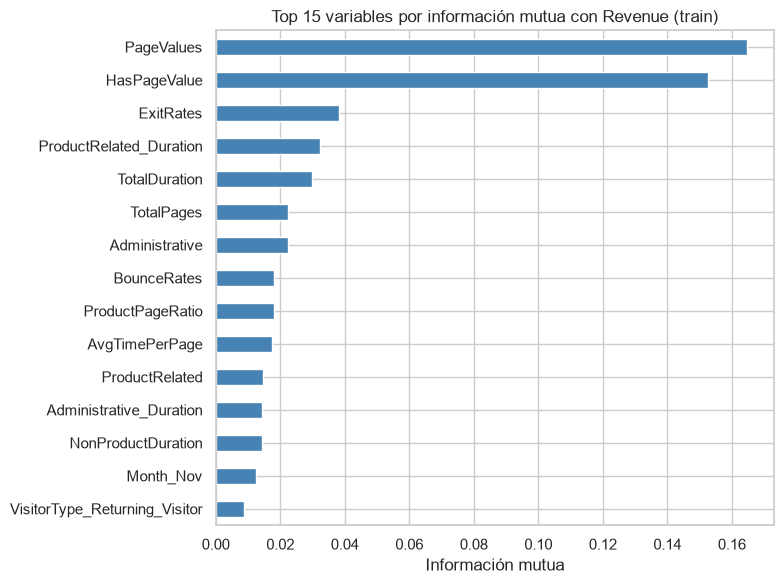

In [21]:
ranking_mi.head(15).sort_values().plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.title("Top 15 variables por información mutua con Revenue (train)")
plt.xlabel("Información mutua")
plt.tight_layout()
plt.show()

Observaciones:

### 4.5 Discretización para reglas de asociación (Apriori)
Apriori trabaja con ítems categóricos. Se aplica discretización por igual frecuencia (terciles) a las variables numéricas. Como muchas tienen demasiados ceros, el cero forma su propia categoría y los valores mayores a 0 se dividen en bajo / medio / alto. `SpecialDay` se binariza. Cada valor lleva el nombre de la variable para que las reglas se lean bien (por ejemplo `PageValues=alto`).

In [22]:
def discretizar_con_ceros(s, nombre, niveles=("bajo", "medio", "alto")):
    out = pd.Series(f"{nombre}=0", index=s.index, dtype=object)
    pos = s > 0
    if pos.sum() > 0:
        rangos = pd.qcut(s[pos].rank(method="first"), q=len(niveles), labels=list(niveles))
        out[pos] = [f"{nombre}={n}" for n in rangos]
    return out

COLS_A_DISCRETIZAR = COLS_CONTEO + COLS_DURACION + COLS_TASAS + ["PageValues"]

df_disc = pd.DataFrame(index=df.index)
for c in COLS_A_DISCRETIZAR:
    df_disc[c] = discretizar_con_ceros(df[c], c)
df_disc["SpecialDay"] = np.where(df["SpecialDay"] > 0, "SpecialDay=cerca", "SpecialDay=lejos")
df_disc["Month"] = "Month=" + df["Month"].astype(str)
df_disc["VisitorType"] = "VisitorType=" + df["VisitorType"]
df_disc["Weekend"] = np.where(df["Weekend"] == 1, "Weekend=si", "Weekend=no")
df_disc["Revenue"] = np.where(df["Revenue"] == 1, "Revenue=compra", "Revenue=no_compra")
df_disc["conjunto"] = df["conjunto"]

df_disc.head()

,Administrative,Informational,ProductRelated,Administrative_Duration,Informational_Duration,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,VisitorType,Weekend,Revenue,conjunto
0,Administrative=0,Informational=0,ProductRelated=bajo,Administrative_Duration=0,Informational_Duration=0,ProductRelated_Duration=0,BounceRates=alto,ExitRates=alto,PageValues=0,SpecialDay=lejos,Month=Feb,VisitorType=Returning_Visitor,Weekend=no,Revenue=no_compra,train
1,Administrative=0,Informational=0,ProductRelated=bajo,Administrative_Duration=0,Informational_Duration=0,ProductRelated_Duration=bajo,BounceRates=0,ExitRates=alto,PageValues=0,SpecialDay=lejos,Month=Feb,VisitorType=Returning_Visitor,Weekend=no,Revenue=no_compra,test
2,Administrative=0,Informational=0,ProductRelated=bajo,Administrative_Duration=0,Informational_Duration=0,ProductRelated_Duration=0,BounceRates=alto,ExitRates=alto,PageValues=0,SpecialDay=lejos,Month=Feb,VisitorType=Returning_Visitor,Weekend=no,Revenue=no_compra,train
3,Administrative=0,Informational=0,ProductRelated=bajo,Administrative_Duration=0,Informational_Duration=0,ProductRelated_Duration=bajo,BounceRates=alto,ExitRates=alto,PageValues=0,SpecialDay=lejos,Month=Feb,VisitorType=Returning_Visitor,Weekend=no,Revenue=no_compra,train
4,Administrative=0,Informational=0,ProductRelated=bajo,Administrative_Duration=0,Informational_Duration=0,ProductRelated_Duration=medio,BounceRates=medio,ExitRates=alto,PageValues=0,SpecialDay=lejos,Month=Feb,VisitorType=Returning_Visitor,Weekend=si,Revenue=no_compra,test


In [23]:
for c in ["PageValues", "ExitRates", "ProductRelated_Duration"]:
    print(df_disc[c].value_counts().to_string(), "\n")

PageValues
PageValues=0        9475
PageValues=alto      910
PageValues=medio     910
PageValues=bajo      910 

ExitRates
ExitRates=alto     4043
ExitRates=medio    4043
ExitRates=bajo     4043
ExitRates=0          76 

ProductRelated_Duration
ProductRelated_Duration=bajo     3859
ProductRelated_Duration=medio    3858
ProductRelated_Duration=alto     3858
ProductRelated_Duration=0         630 



## 5. Exportar los datasets

In [24]:
os.makedirs("data", exist_ok=True)

df.to_csv("data/datos_limpios.csv", index=False)
df_cod.to_csv("data/datos_codificados.csv", index=False)
df_disc.to_csv("data/datos_discretizados.csv", index=False)

for nombre in ["datos_limpios", "datos_codificados", "datos_discretizados"]:
    chk = pd.read_csv(f"data/{nombre}.csv")
    print(f"{nombre}.csv -> {chk.shape[0]} filas x {chk.shape[1]} columnas | nulos: {chk.isna().sum().sum()}")

datos_limpios.csv -> 12205 filas x 26 columnas | nulos: 0
datos_codificados.csv -> 12205 filas x 77 columnas | nulos: 0
datos_discretizados.csv -> 12205 filas x 15 columnas | nulos: 0


## 6. Resumen del preprocesamiento

In [25]:
print(f"Filas originales            : {n_original}")
print(f"Filas tras la limpieza      : {len(df)} (duplicados eliminados: {n_original - len(df)})")
print(f"Variables originales        : {df_raw.shape[1]}")
print(f"Variables nuevas            : {len(COLS_NUEVAS)} -> {COLS_NUEVAS}")
print(f"Columnas en datos_codificados: {df_cod.shape[1]}")
print(f"Partición                   : {(df['conjunto'] == 'train').sum()} train / {(df['conjunto'] == 'test').sum()} test")
print(f"Tasa de compra              : {df['Revenue'].mean() * 100:.2f} %")

Filas originales            : 12330
Filas tras la limpieza      : 12205 (duplicados eliminados: 125)
Variables originales        : 18
Variables nuevas            : 7 -> ['TotalPages', 'NonProductDuration', 'ProductPageRatio', 'TotalDuration', 'AvgTimePerPage', 'IsSpecialDay', 'HasPageValue']
Columnas en datos_codificados: 77
Partición                   : 9764 train / 2441 test
Tasa de compra              : 15.63 %


## 7. Uso de los archivos en los demás notebooks

Clasificación (`datos_codificados.csv`)
```python
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/datos_codificados.csv")
train, test = df[df.conjunto == "train"], df[df.conjunto == "test"]
X_train, y_train = train.drop(columns=["Revenue", "conjunto"]), train["Revenue"]
X_test,  y_test  = test.drop(columns=["Revenue", "conjunto"]),  test["Revenue"]

# solo si el modelo lo necesita: ajustar con train
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
```
Las clases están desbalanceadas, así que además de accuracy hay que reportar precision, recall, F1 y la matriz de confusión.

Regresión (`datos_limpios.csv`, objetivo `ProductRelated_Duration`)
```python
df = pd.read_csv("data/datos_limpios.csv")
excluir = ["ProductRelated_Duration", "TotalDuration", "AvgTimePerPage", "conjunto"]
X = pd.get_dummies(df.drop(columns=excluir), drop_first=True, dtype=int)
y = df["ProductRelated_Duration"]
train_mask = df["conjunto"] == "train"
```

Clustering (`datos_limpios.csv`)
```python
cols = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration",
        "ProductRelated", "BounceRates", "ExitRates"]
# normalizar antes de K-Means y no incluir Revenue para agrupar
```

Reglas de asociación (`datos_discretizados.csv`)
```python
df = pd.read_csv("data/datos_discretizados.csv").drop(columns="conjunto")
transacciones = pd.get_dummies(df, prefix="", prefix_sep="").astype(bool)
# from mlxtend.frequent_patterns import apriori, association_rules
```